In [2]:

# Cell 1 — Setup and Data Loading

import os
import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")

# Find the project root whether the notebook starts in
# the project folder or inside the notebooks folder.
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src" / "analytics" / "load_data.py").exists():
    raise FileNotFoundError(
        "Could not find src/analytics/load_data.py. "
        "Please check that the notebook is saved inside the macroops-ai project."
    )

# Use the project root for all relative file paths.
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Create the folder where charts will be saved.
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

# Load all datasets.
from src.analytics.load_data import load_all

data = load_all()

orders = data["orders"].copy()
picking = data["picking"].copy()
delivery = data["delivery"].copy()
inventory = data["inventory"].copy()
workforce = data["workforce"].copy()

# Parse timestamps.
orders["order_time"] = pd.to_datetime(orders["order_time"])
orders["promised_time"] = pd.to_datetime(orders["promised_time"])
orders["actual_delivery_time"] = pd.to_datetime(
    orders["actual_delivery_time"]
)

picking["pick_start"] = pd.to_datetime(picking["pick_start"])
picking["pick_end"] = pd.to_datetime(picking["pick_end"])

print("All datasets loaded and timestamps parsed.")
print(f"\nProject root: {PROJECT_ROOT}")
print("\nDataset Summary:")
print(f"  Orders:    {len(orders):,} records")
print(f"  Picking:   {len(picking):,} records")
print(f"  Delivery:  {len(delivery):,} records")
print(f"  Inventory: {len(inventory):,} records")
print(f"  Workforce: {len(workforce):,} records")
print(f"\nFigures will be saved to: {FIGURES_DIR}")


Loading all MacroOps AI datasets...
Loaded orders: 100,000 rows × 10 columns
Loaded picking: 25,000 rows × 7 columns
Loaded delivery: 25,000 rows × 7 columns
Loaded inventory: 40,000 rows × 7 columns
Loaded workforce: 10,000 rows × 6 columns
Total records loaded: 200,000
All datasets loaded and timestamps parsed.

Project root: c:\Users\shivy\Desktop\macroops-ai

Dataset Summary:
  Orders:    100,000 records
  Picking:   25,000 records
  Delivery:  25,000 records
  Inventory: 40,000 records
  Workforce: 10,000 records

Figures will be saved to: c:\Users\shivy\Desktop\macroops-ai\reports\figures


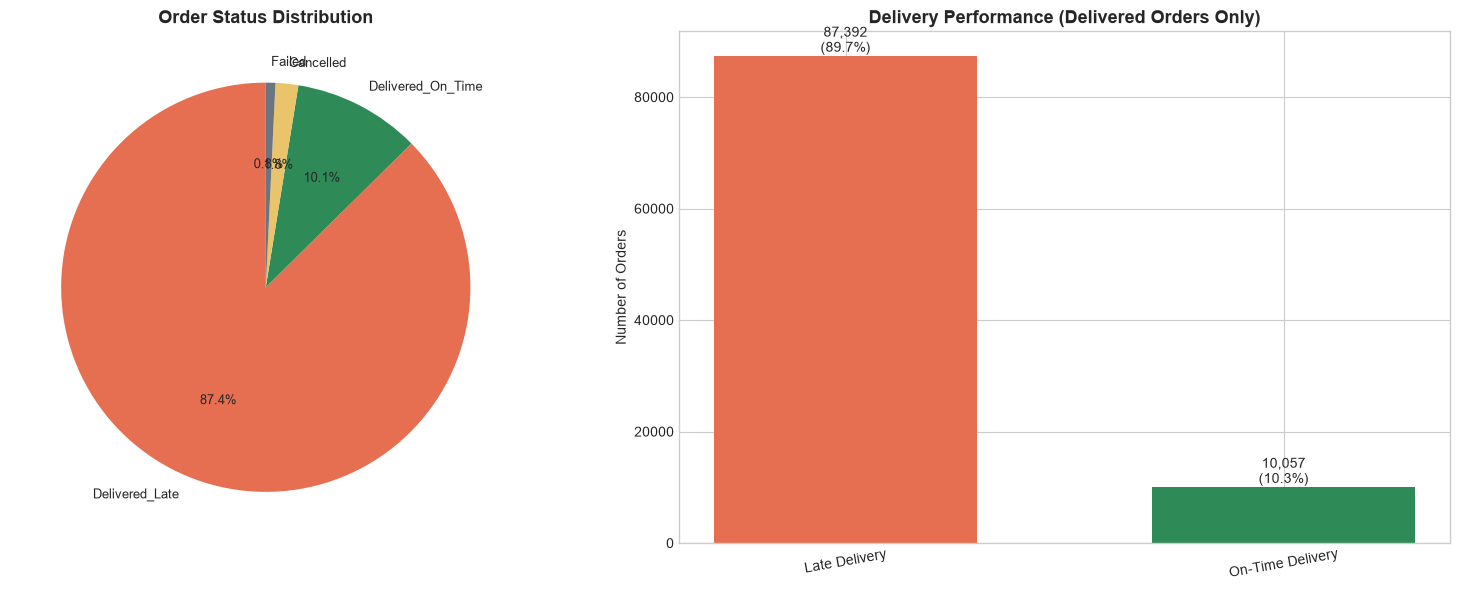


Order Status Counts:
status
Delivered_Late       87392
Delivered_On_Time    10057
Cancelled             1795
Failed                 756

Total delivered orders: 97,449
Late deliveries: 87,392 (89.68%)
On-time deliveries: 10,057 (10.32%)

Chart saved to reports/figures/01_order_status.png


In [3]:

# Cell 2 — Order Status Distribution and SLA Performance

# Count orders by status.
status_counts = orders["status"].value_counts()

# Calculate delivery performance using delivered orders only.
delivered_statuses = ["Delivered_Late", "Delivered_On_Time"]
delivered_orders = orders[orders["status"].isin(delivered_statuses)]

late_count = (delivered_orders["status"] == "Delivered_Late").sum()
on_time_count = (delivered_orders["status"] == "Delivered_On_Time").sum()
total_delivered = len(delivered_orders)

late_rate = (late_count / total_delivered * 100) if total_delivered else 0
on_time_rate = (on_time_count / total_delivered * 100) if total_delivered else 0

# Create two charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Order status distribution.
colors = {
    "Delivered_On_Time": "#2E8B57",
    "Delivered_Late": "#E76F51",
    "Cancelled": "#E9C46A",
    "Failed": "#6C757D",
}

pie_colors = [colors.get(status, "#808080") for status in status_counts.index]

axes[0].pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=pie_colors,
    textprops={"fontsize": 9},
)
axes[0].set_title("Order Status Distribution", fontsize=13, fontweight="bold")

# Chart 2: Delivered orders only.
performance_labels = ["Late Delivery", "On-Time Delivery"]
performance_counts = [late_count, on_time_count]
performance_colors = ["#E76F51", "#2E8B57"]

bars = axes[1].bar(
    performance_labels,
    performance_counts,
    color=performance_colors,
    width=0.6,
)

axes[1].set_title(
    "Delivery Performance (Delivered Orders Only)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis="x", rotation=10)

for bar, count in zip(bars, performance_counts):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({count / total_delivered * 100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_order_status.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nOrder Status Counts:")
print(status_counts.to_string())

print(f"\nTotal delivered orders: {total_delivered:,}")
print(f"Late deliveries: {late_count:,} ({late_rate:.2f}%)")
print(f"On-time deliveries: {on_time_count:,} ({on_time_rate:.2f}%)")
print("\nChart saved to reports/figures/01_order_status.png")


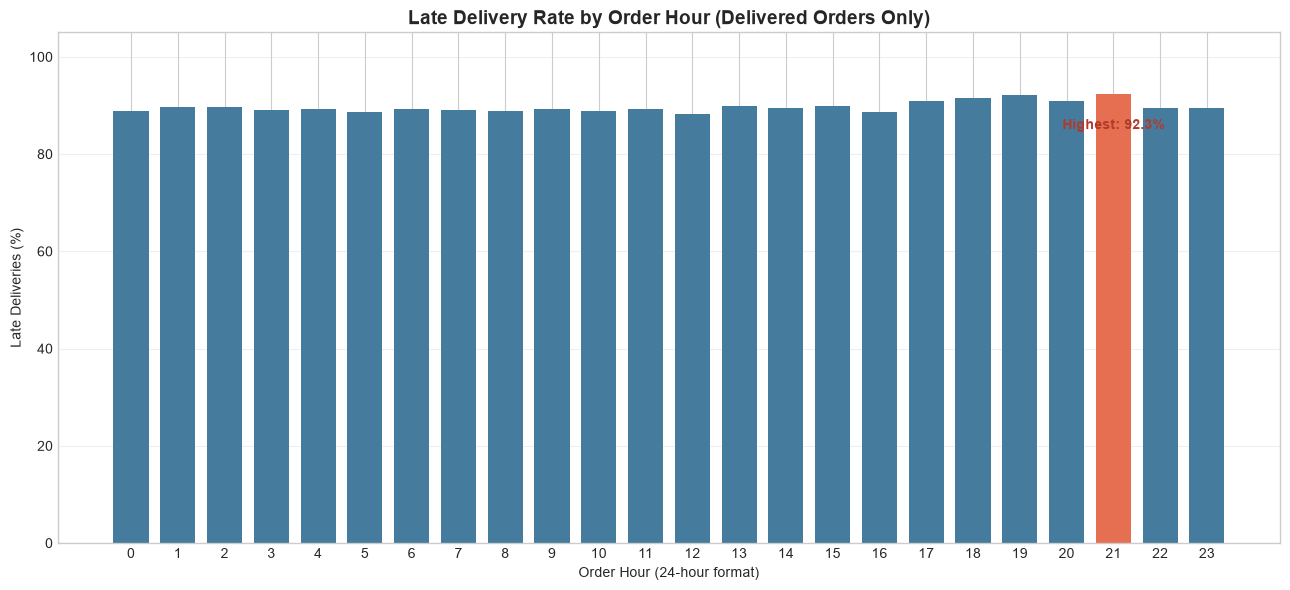


Hourly Delivery Performance:
            total_delivered  late_deliveries  late_delivery_rate
order_hour                                                      
0                      4196             3726               88.80
1                      4140             3715               89.73
2                      4179             3745               89.61
3                      3991             3553               89.03
4                      4057             3622               89.28
5                      4075             3612               88.64
6                      4003             3576               89.33
7                      4009             3573               89.12
8                      4032             3579               88.76
9                      4054             3617               89.22
10                     4061             3607               88.82
11                     4103             3662               89.25
12                     4027             3555               8

In [4]:

# Cell 3 — Late Delivery Rate by Order Hour

# Keep delivered orders only for a fair comparison.
delivered = orders[
    orders["status"].isin(["Delivered_Late", "Delivered_On_Time"])
].copy()

# Extract the hour from each order's timestamp.
delivered["order_hour"] = delivered["order_time"].dt.hour

# Calculate total and late deliveries for each hour.
hourly_stats = delivered.groupby("order_hour").agg(
    total_delivered=("status", "size"),
    late_deliveries=("status", lambda s: (s == "Delivered_Late").sum()),
)

# Calculate late-delivery percentage for each hour.
hourly_stats["late_delivery_rate"] = (
    hourly_stats["late_deliveries"]
    / hourly_stats["total_delivered"]
    * 100
)

# Find the hours with the highest and lowest late-delivery rates.
peak_hour = hourly_stats["late_delivery_rate"].idxmax()
lowest_hour = hourly_stats["late_delivery_rate"].idxmin()

# Plot the hourly late-delivery rate.
fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    hourly_stats.index,
    hourly_stats["late_delivery_rate"],
    color=[
        "#E76F51" if hour == peak_hour else "#457B9D"
        for hour in hourly_stats.index
    ],
    width=0.75,
)

ax.set_title(
    "Late Delivery Rate by Order Hour (Delivered Orders Only)",
    fontsize=14,
    fontweight="bold",
)
ax.set_xlabel("Order Hour (24-hour format)")
ax.set_ylabel("Late Deliveries (%)")
ax.set_xticks(range(24))
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)

# Label the highest-rate hour.
ax.annotate(
    f"Highest: {hourly_stats.loc[peak_hour, 'late_delivery_rate']:.1f}%",
    xy=(peak_hour, hourly_stats.loc[peak_hour, "late_delivery_rate"]),
    xytext=(0, -25),
    textcoords="offset points",
    ha="center",
    color="#B23A2B",
    fontweight="bold",
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_hourly_sla_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nHourly Delivery Performance:")
print(hourly_stats.round(2).to_string())

print(f"\nHighest late-delivery rate: {peak_hour:02d}:00 "
      f"({hourly_stats.loc[peak_hour, 'late_delivery_rate']:.2f}%)")
print(f"Lowest late-delivery rate: {lowest_hour:02d}:00 "
      f"({hourly_stats.loc[lowest_hour, 'late_delivery_rate']:.2f}%)")

print("\nChart saved to reports/figures/02_hourly_sla_analysis.png")


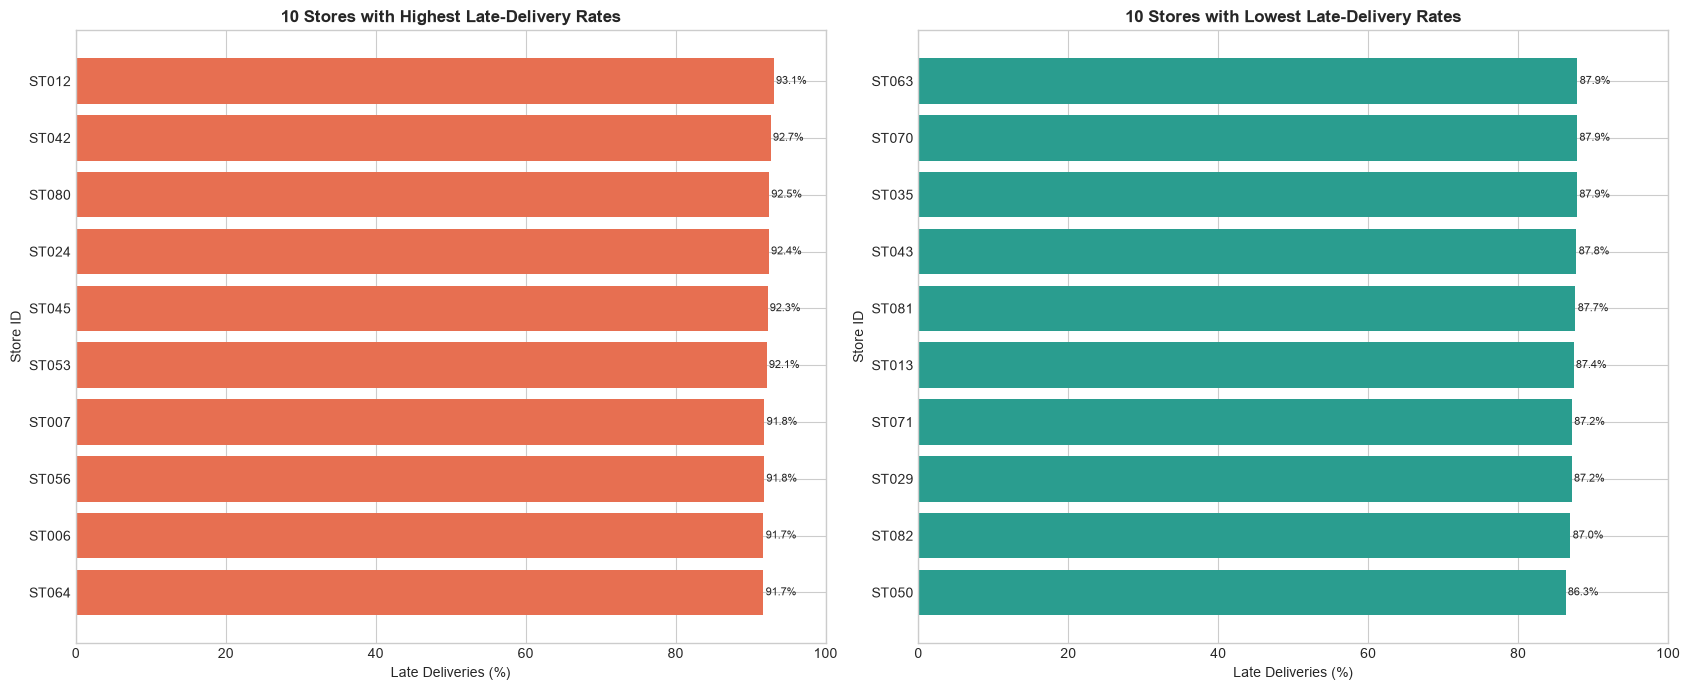


10 Stores with Highest Late-Delivery Rates:
          total_delivered  late_deliveries  on_time_deliveries  late_delivery_rate
store_id                                                                          
ST012                 956              890                  66               93.10
ST042                 944              875                  69               92.69
ST080                 956              884                  72               92.47
ST024                 965              892                  73               92.44
ST045                 957              883                  74               92.27
ST053                 917              845                  72               92.15
ST007                 968              889                  79               91.84
ST056                1001              919                  82               91.81
ST006                 991              909                  82               91.73
ST064                1026              941

In [5]:

# Cell 4 — Store Performance Analysis

# Use delivered orders only when calculating late-delivery rates.
store_orders = orders[
    orders["status"].isin(["Delivered_Late", "Delivered_On_Time"])
].copy()

# Count total, late, and on-time deliveries for each store.
store_performance = store_orders.groupby("store_id").agg(
    total_delivered=("status", "size"),
    late_deliveries=("status", lambda s: (s == "Delivered_Late").sum()),
    on_time_deliveries=("status", lambda s: (s == "Delivered_On_Time").sum()),
)

# Calculate late-delivery rate for each store.
store_performance["late_delivery_rate"] = (
    store_performance["late_deliveries"]
    / store_performance["total_delivered"]
    * 100
)

# Sort stores from worst to best by late-delivery rate.
store_performance = store_performance.sort_values(
    "late_delivery_rate", ascending=False
)

worst_stores = store_performance.head(10)
best_stores = store_performance.tail(10).sort_values(
    "late_delivery_rate", ascending=True
)

# Plot the 10 worst and 10 best stores.
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

axes[0].barh(
    worst_stores.index.astype(str),
    worst_stores["late_delivery_rate"],
    color="#E76F51",
)
axes[0].set_title("10 Stores with Highest Late-Delivery Rates", fontweight="bold")
axes[0].set_xlabel("Late Deliveries (%)")
axes[0].set_ylabel("Store ID")
axes[0].invert_yaxis()
axes[0].set_xlim(0, 100)

for i, value in enumerate(worst_stores["late_delivery_rate"]):
    axes[0].text(value + 0.3, i, f"{value:.1f}%", va="center", fontsize=8)

axes[1].barh(
    best_stores.index.astype(str),
    best_stores["late_delivery_rate"],
    color="#2A9D8F",
)
axes[1].set_title("10 Stores with Lowest Late-Delivery Rates", fontweight="bold")
axes[1].set_xlabel("Late Deliveries (%)")
axes[1].set_ylabel("Store ID")
axes[1].set_xlim(0, 100)

for i, value in enumerate(best_stores["late_delivery_rate"]):
    axes[1].text(value + 0.3, i, f"{value:.1f}%", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_store_performance.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n10 Stores with Highest Late-Delivery Rates:")
print(worst_stores.round(2).to_string())

print("\n10 Stores with Lowest Late-Delivery Rates:")
print(best_stores.round(2).to_string())

print("\nChart saved to reports/figures/03_store_performance.png")


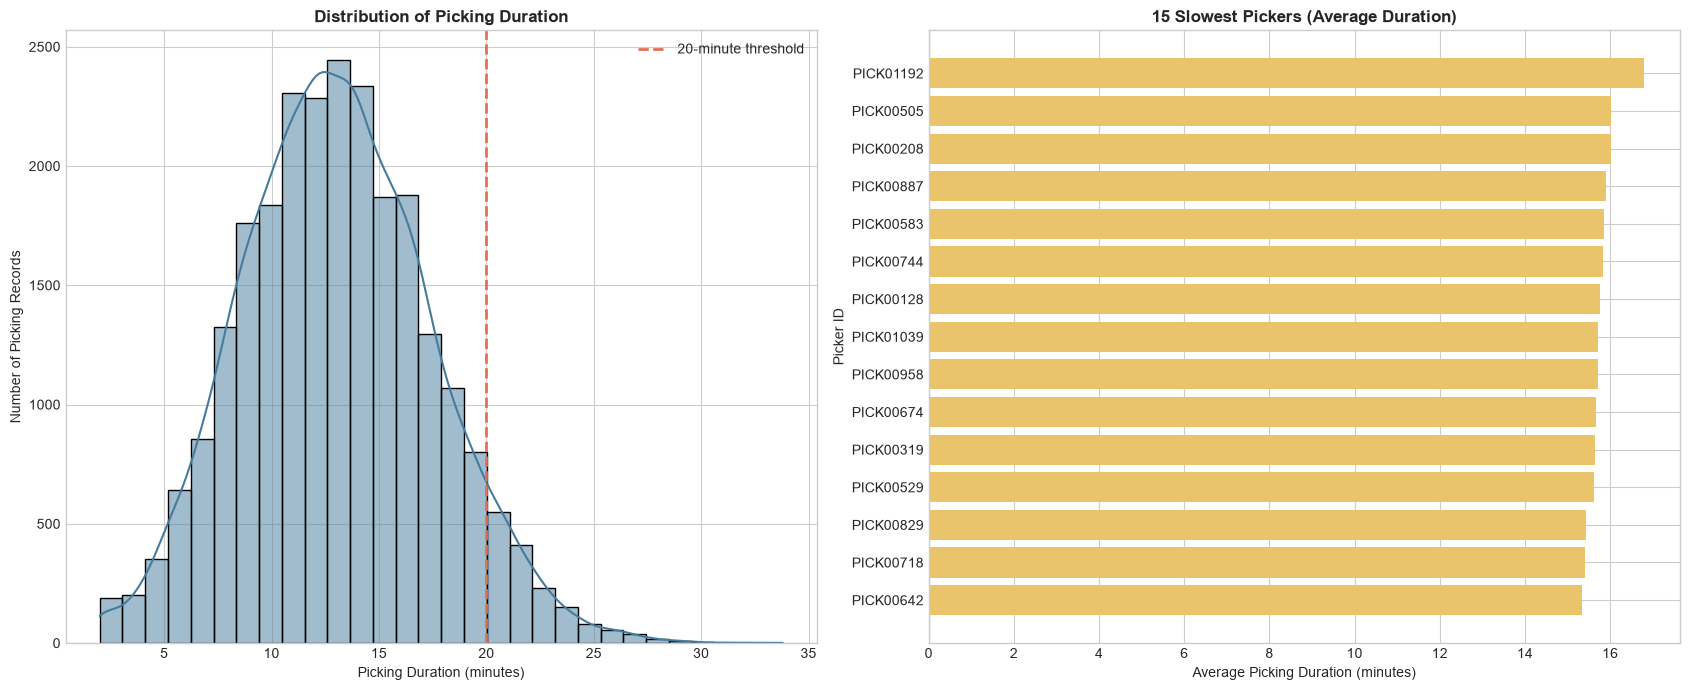

Picking Duration Summary:
  Valid picking records: 25,000
  Average duration: 13.03 minutes
  Median duration: 12.90 minutes
  Records taking more than 20 minutes: 1,547 (6.19%)
  Total missing items recorded: 3,100

15 Slowest Pickers by Average Duration:
           orders_picked  avg_pick_duration
picker_id                                  
PICK01192             10              16.80
PICK00505             13              16.03
PICK00208             20              16.01
PICK00887             13              15.89
PICK00583             22              15.85
PICK00744             13              15.84
PICK00128             21              15.77
PICK01039             15              15.72
PICK00958             12              15.72
PICK00674             16              15.66
PICK00319             13              15.65
PICK00529             23              15.63
PICK00829             17              15.42
PICK00718             19              15.42
PICK00642             12              1

In [6]:

# Cell 5 — Picking Duration and Slow Pickers

# Remove records with missing or invalid picking durations.
picking_analysis = picking[
    picking["pick_duration_minutes"].notna()
    & (picking["pick_duration_minutes"] >= 0)
].copy()

# Summary statistics for picking duration.
avg_pick_duration = picking_analysis["pick_duration_minutes"].mean()
median_pick_duration = picking_analysis["pick_duration_minutes"].median()
slow_pick_count = (
    picking_analysis["pick_duration_minutes"] > 20
).sum()
missing_item_count = picking_analysis["items_missing"].sum()

# Calculate average picking duration for each picker.
picker_performance = (
    picking_analysis.groupby("picker_id")
    .agg(
        orders_picked=("order_id", "count"),
        avg_pick_duration=("pick_duration_minutes", "mean"),
    )
    .sort_values("avg_pick_duration", ascending=False)
)

# Select the 15 slowest pickers by average duration.
slowest_pickers = picker_performance.head(15).sort_values(
    "avg_pick_duration", ascending=True
)

# Create two charts.
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Chart 1: Picking duration distribution.
sns.histplot(
    data=picking_analysis,
    x="pick_duration_minutes",
    bins=30,
    kde=True,
    color="#457B9D",
    ax=axes[0],
)
axes[0].axvline(
    20,
    color="#E76F51",
    linestyle="--",
    linewidth=2,
    label="20-minute threshold",
)
axes[0].set_title("Distribution of Picking Duration", fontweight="bold")
axes[0].set_xlabel("Picking Duration (minutes)")
axes[0].set_ylabel("Number of Picking Records")
axes[0].legend()

# Chart 2: Slowest pickers by average duration.
axes[1].barh(
    slowest_pickers.index.astype(str),
    slowest_pickers["avg_pick_duration"],
    color="#E9C46A",
)
axes[1].set_title("15 Slowest Pickers (Average Duration)", fontweight="bold")
axes[1].set_xlabel("Average Picking Duration (minutes)")
axes[1].set_ylabel("Picker ID")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_picking_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Picking Duration Summary:")
print(f"  Valid picking records: {len(picking_analysis):,}")
print(f"  Average duration: {avg_pick_duration:.2f} minutes")
print(f"  Median duration: {median_pick_duration:.2f} minutes")
print(f"  Records taking more than 20 minutes: {slow_pick_count:,} "
      f"({slow_pick_count / len(picking_analysis) * 100:.2f}%)")
print(f"  Total missing items recorded: {missing_item_count:,}")

print("\n15 Slowest Pickers by Average Duration:")
print(slowest_pickers.sort_values(
    "avg_pick_duration", ascending=False
).round(2).to_string())

print("\nChart saved to reports/figures/04_picking_analysis.png")


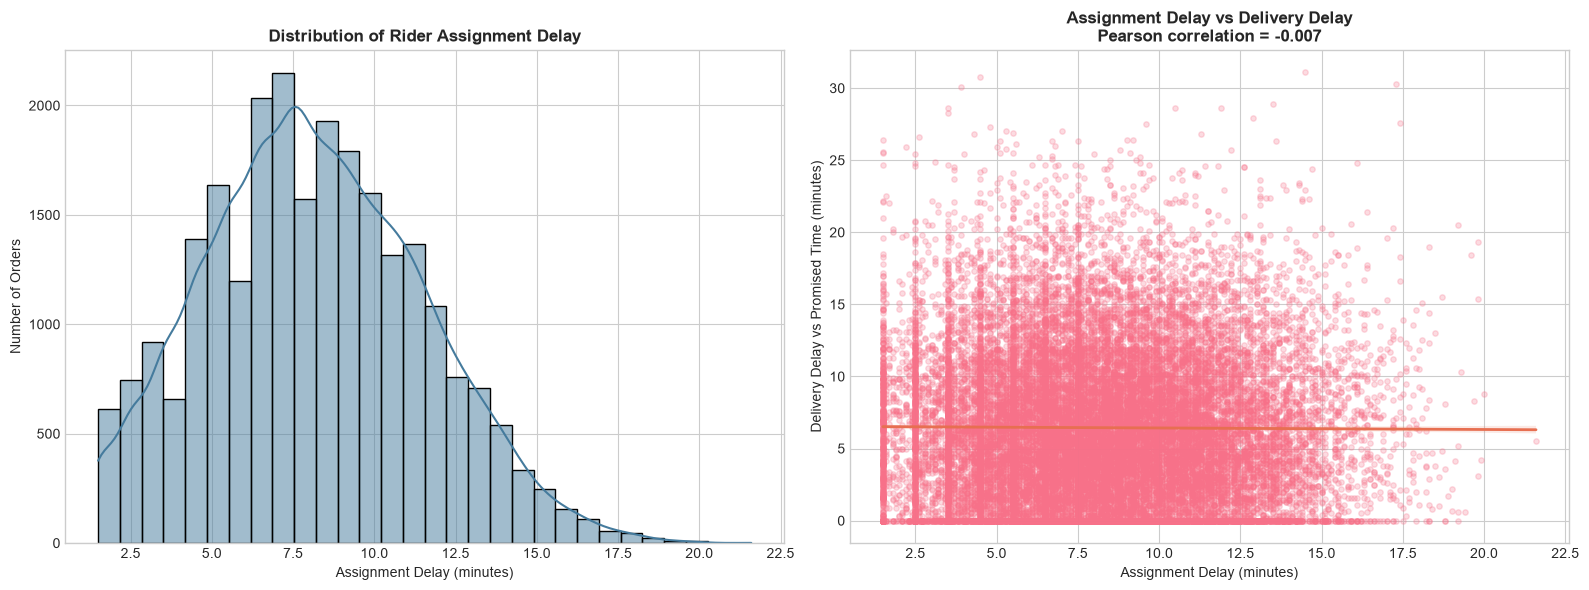

Assignment and Delivery Delay Summary:
  Matched delivery records: 25,000
  Average assignment delay: 8.17 minutes
  Average delivery delay vs promised time: 6.45 minutes
  Pearson correlation: -0.007
  Interpretation: Weak negative linear relationship

Correlation does not prove that assignment delay causes delivery delay.
Chart saved to reports/figures/05_delivery_analysis.png


In [7]:

# Cell 6 — Assignment Delay and Delivery Delay Correlation

# Keep the relevant columns from orders.
order_delays = orders[
    ["order_id", "delivery_delay_minutes", "status"]
].copy()

# Match delivery records to their corresponding orders.
delay_analysis = delivery.merge(
    order_delays,
    on="order_id",
    how="inner",
    validate="one_to_one",
)

# Remove rows with missing delay values.
delay_analysis = delay_analysis.dropna(
    subset=["assignment_delay_minutes", "delivery_delay_minutes"]
)

# Calculate Pearson correlation between assignment delay and delivery delay.
correlation = delay_analysis[
    ["assignment_delay_minutes", "delivery_delay_minutes"]
].corr().iloc[0, 1]

# Summary statistics.
avg_assignment_delay = delay_analysis["assignment_delay_minutes"].mean()
avg_delivery_delay = delay_analysis["delivery_delay_minutes"].mean()

# Create two visualizations.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Assignment delay distribution.
sns.histplot(
    data=delay_analysis,
    x="assignment_delay_minutes",
    bins=30,
    kde=True,
    color="#457B9D",
    ax=axes[0],
)
axes[0].set_title("Distribution of Rider Assignment Delay", fontweight="bold")
axes[0].set_xlabel("Assignment Delay (minutes)")
axes[0].set_ylabel("Number of Orders")

# Chart 2: Assignment delay vs delivery delay.
sns.regplot(
    data=delay_analysis,
    x="assignment_delay_minutes",
    y="delivery_delay_minutes",
    scatter_kws={"alpha": 0.25, "s": 15},
    line_kws={"color": "#E76F51", "linewidth": 2},
    ax=axes[1],
)
axes[1].set_title(
    f"Assignment Delay vs Delivery Delay\nPearson correlation = {correlation:.3f}",
    fontweight="bold",
)
axes[1].set_xlabel("Assignment Delay (minutes)")
axes[1].set_ylabel("Delivery Delay vs Promised Time (minutes)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_delivery_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Assignment and Delivery Delay Summary:")
print(f"  Matched delivery records: {len(delay_analysis):,}")
print(f"  Average assignment delay: {avg_assignment_delay:.2f} minutes")
print(f"  Average delivery delay vs promised time: {avg_delivery_delay:.2f} minutes")
print(f"  Pearson correlation: {correlation:.3f}")

if correlation >= 0.7:
    interpretation = "Strong positive linear relationship"
elif correlation >= 0.3:
    interpretation = "Moderate positive linear relationship"
elif correlation > 0:
    interpretation = "Weak positive linear relationship"
elif correlation <= -0.7:
    interpretation = "Strong negative linear relationship"
elif correlation <= -0.3:
    interpretation = "Moderate negative linear relationship"
elif correlation < 0:
    interpretation = "Weak negative linear relationship"
else:
    interpretation = "No linear relationship"

print(f"  Interpretation: {interpretation}")
print("\nCorrelation does not prove that assignment delay causes delivery delay.")
print("Chart saved to reports/figures/05_delivery_analysis.png")
